# Practicum 1: probing correct and counterfactual passages

> **Search Solutions Tutorial Day, 24 November 2026**  
> Inside Language Models: From Probing to Mechanistic Interpretability  
> Kevin Roitero and Riccardo Lunardi, University of Udine

**Research question:** _Can a linear probe distinguish correct and counterfactual passages for unseen questions, using the model's activations before it answers?_

All experiment code is in this notebook. The only required external files are `data/pilot.json` and `data/activations.npz`. 

Run the cells in order. By default, saved responses and activations are used, so **no GPU is needed**. In Colab, upload `practicum1_upload.zip` when prompted. To regenerate responses and activations from the same checkpoint, set `USE_SAVED_DATA = False` and select a GPU runtime.

We use one fixed split of questions: approximately 80% for training and 20% for testing. We train a separate linear probe at each layer and plot its test accuracy to explore how well the passage labels can be decoded. Both passages for a question always stay together.

This is an exploratory experiment. Decoding the passage labels does not establish an explicit internal truth variable or its causal use.

In [64]:
from pathlib import Path

USE_SAVED_DATA = True  # The new accuracy-prompt responses and activations are included.
DEVICE = "auto"  # Use a local or Colab CUDA GPU when available; alternatively "cuda:1" or "cpu".
DATA = Path("data")
SEED = 42
TEST_FRACTION = 0.20

## 1. Dependencies

Install dependencies from the shared `requirements.txt` at the repository root before running the notebook.

## How is the data structured?

The pilot data contains two types of record: **questions**, which define the correct and counterfactual answers, and **trials**, which record individual model runs.

### Questions

Each question is stored as a record like this:

```json
{
    "id": "capital_01",
    "category": "capitals",
    "question": "What is the capital of Australia?",
    "gold_answer": "Canberra",
    "counterfactual_answer": "Melbourne",
    "statement": "The capital of Australia is {answer}.",
    "gold_aliases": [],
    "counterfactual_aliases": []
}
```

`question` is what we ask the model. `gold_answer` is the correct answer, while `counterfactual_answer` is the incorrect answer used in the counterfactual passage.

`statement` is a template for building the passages: replacing `{answer}` with either answer produces the correct or counterfactual version. The alias lists contain alternative forms accepted when checking the model's response.

### Trials

A trial records the prompt and response for a question under one of three conditions:

- `closed_book`: the question without a passage;
- `gold`: the question with the correct passage;
- `counterfactual`: the question with the counterfactual passage.

Here is an example, with the token ID list abbreviated:

```json
{
    "id": "capital_01",
    "condition": "counterfactual",
    "prompt": "Answer the question as accurately as possible. The accompanying passage may contain factual errors. Give only the answer entity or value, without explanation.\n\nPassage: The capital of Australia is Melbourne.\n\nQuestion: What is the capital of Australia?",
    "response": "Melbourne",
    "truncated": false,
    "prompt_token_ids": [
    ...
    ]
}
```

`prompt` contains the task instructions, the passage when present, and the question. `response` is the text generated by the model. `truncated` indicates whether generation reached the token limit without an end-of-sequence token. `prompt_token_ids` stores the exact input tokens, including the chat template.

These token IDs are **not hidden-state activations**. A later cell uses them to extract the model's hidden states at the last prompt token, before any answer tokens are generated. Those activation vectors are the inputs used to train and evaluate the probes.


In [65]:
import json
import re
import unicodedata
import zipfile

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# In Colab, upload practicum1_upload.zip if the input data are not present. 
if not (DATA / "pilot.json").is_file():
    from google.colab import files
    uploaded = files.upload()  # Upload practicum1_upload.zip.
    archive = next(name for name in uploaded if name.endswith(".zip"))
    DATA.mkdir(exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        for name in ("pilot.json", "activations.npz"):
            (DATA / name).write_bytes(z.read("data/" + name))

pilot = json.loads((DATA / "pilot.json").read_text(encoding="utf-8"))
questions = pilot["questions"]
trials = {(t["id"], t["condition"]): t for t in pilot["trials"]}
assert len(trials) == len(pilot["trials"]), "Duplicate trials"
print("Experiment:", pilot["provenance"]["experiment"])
print("Model:", pilot["model"]["id"])
print("Checkpoint:", pilot["model"]["revision"])

Experiment: probing
Model: Qwen/Qwen2.5-1.5B-Instruct
Checkpoint: 989aa7980e4cf806f80c7fef2b1adb7bc71aa306


With `USE_SAVED_DATA = False`, the next cell generates 150 responses: each question without a passage, with a correct passage, and with a counterfactual passage. Both passage conditions use the same instruction:

> Answer the question as accurately as possible. The accompanying passage may contain factual errors. Give only the answer entity or value, without explanation.

The closed-book condition asks for an accurate answer without mentioning an accompanying passage. Each trial uses a separate conversation, greedy decoding, and a limit of 32 new tokens. Using a precision other than bfloat16 may change the responses and therefore the selected questions.

In [66]:
if not USE_SAVED_DATA:
    import subprocess
    import sys
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed

    set_seed(SEED)

    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu") if DEVICE == "auto" else torch.device(DEVICE)
    if device.type == "cuda":
        torch.cuda.set_device(device.index or 0)
        dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    else:
        dtype = torch.float32
    
    print("Model inference:", device, dtype, "(original pilot: bfloat16)")

    # Initialize the model and tokenizer
    model = AutoModelForCausalLM.from_pretrained(pilot["model"]["id"], revision=pilot["model"]["revision"], torch_dtype=dtype).to(device)
    model.eval().requires_grad_(False)

    tokenizer = AutoTokenizer.from_pretrained(pilot["model"]["id"], revision=pilot["model"]["revision"])
    # Rebuild the prompts and their token IDs; tokenization must match the current instruction.
    passage_instruction = (
        "Answer the question as accurately as possible. "
        "The accompanying passage may contain factual errors. "
        "Give only the answer entity or value, without explanation."
    )
    closed_book_instruction = (
        "Answer the question as accurately as possible. "
        "Give only the answer entity or value, without explanation."
    )
    questions_by_id = {q["id"]: q for q in questions}
    for t in trials.values():
        q = questions_by_id[t["id"]]
        
        if t["condition"] == "closed_book":
            prompt = f"{closed_book_instruction}\n\nQuestion: {q['question']}"
        else:
            passage = q["statement"].format(answer=q[f"{t['condition']}_answer"])
            prompt = f"{passage_instruction}\n\nPassage: {passage}\n\nQuestion: {q['question']}"
        
        t["prompt"] = prompt
        
        encoded = tokenizer.apply_chat_template(
            [{"role": "user", "content": prompt}], tokenize=True,
            add_generation_prompt=True, enable_thinking=False,
        )
        
        # Handle both transformers >= 5.0 (BatchEncoding) and < 5.0 (list[int])
        t["prompt_token_ids"] = encoded["input_ids"] if hasattr(encoded, "keys") else encoded

    pilot["provenance"] = {
        "experiment": "probing",
        "passage_instruction": passage_instruction,
        "closed_book_instruction": closed_book_instruction,
        "device": str(device), "dtype": str(dtype),
    }

    eos = model.generation_config.eos_token_id
    eos = {eos} if isinstance(eos, int) else set(eos or [])

    # For each of the trials, generate a response from the model and store it in the trial dictionary.    
    for i, t in enumerate(trials.values()):
        ids = torch.tensor([t["prompt_token_ids"]], device=model.get_input_embeddings().weight.device)
        
        with torch.inference_mode():
            output = model.generate(input_ids=ids, attention_mask=torch.ones_like(ids), max_new_tokens=32,
                                    num_beams=1, use_cache=True, 
                                    pad_token_id=tokenizer.pad_token_id if tokenizer.pad_token_id is not None else tokenizer.eos_token_id)
        
        new_ids = output[0, ids.shape[1]:].tolist()
        t["response"] = tokenizer.decode(new_ids, skip_special_tokens=True).strip()
        t["truncated"] = len(new_ids) >= 32 and (not new_ids or new_ids[-1] not in eos)
        
        print(f"\rResponses: {i + 1}/{len(trials)}", end="")
   
    print()

## 2. From model responses to question pairs

In the pilot, the model received each question on its own, with a correct passage, or with a counterfactual passage. We retain questions answered correctly without context. Each contributes two examples: **0 = correct passage**, **1 = counterfactual passage**. Generated responses determine which questions are retained; they are not features for the probe.

Both versions of a question belong to the same group. We always keep them together when splitting the data into training and evaluation sets.

In [67]:
def normalize_text(text):
    text = unicodedata.normalize("NFKD", text).casefold()
    text = "".join(c for c in text if not unicodedata.combining(c))
    return " ".join(re.sub(r"[^\w\s]", " ", text).split())

# Given the accents and punctuation, we normalize the text and check if the model's response matches any of the aliases for the answer.
def answer_matches(trial, question, kind):
    aliases = [question[f"{kind}_answer"], *question[f"{kind}_aliases"]]
    return not trial["truncated"] and normalize_text(trial["response"]) in {normalize_text(x) for x in aliases}

# Let's select only the cases where the model answered correctly without a passage
selected = [q for q in questions if answer_matches(trials[(q["id"], "closed_book")], q, "gold")]

# Examples will contain one example for each of the selected questions, with the gold passage and the counterfactual passage. 
# The label will be 0 for the gold passage and 1 for the counterfactual passage.
examples = []
for q in selected:
    # For each of the correctly answered questions, we create two examples: one with the gold passage and one with the counterfactual passage.
    for condition, label in [("gold", 0), ("counterfactual", 1)]:
        t = trials[(q["id"], condition)]
        examples.append({"example_id": f"{q['id']}__{condition}", "group": q["id"],
                         "category": q["category"], "y": label, "question": q["question"],
                         "passage": q["statement"].format(answer=q[f"{condition}_answer"]),
                         "prompt": t["prompt"], "tokens": t["prompt_token_ids"]})

y = np.asarray([e["y"] for e in examples])
groups = np.asarray([e["group"] for e in examples])
example_ids = [e["example_id"] for e in examples]

print(f"Correct answers without a passage: {len(selected)}/{len(questions)}")
for condition, kind in [("gold", "gold"), ("counterfactual", "counterfactual")]:
    matches = sum(answer_matches(trials[(q["id"], condition)], q, kind) for q in questions)
    print(f"Answers matching the {condition} passage: {matches}/{len(questions)}")

# As input to the probe, we will use the selected examples because they are the ones where the model answered correctly without a passage.
# The probe will be trained to predict whether the passage is gold or counterfactual based on the hidden states of the model.
print(f"Probe data: {len(selected)} groups, {len(examples)} passages, class counts {np.bincount(y)}")
print("Example:", examples[0]["passage"], "|", examples[1]["passage"])

Correct answers without a passage: 47/50
Answers matching the gold passage: 50/50
Answers matching the counterfactual passage: 50/50
Probe data: 47 groups, 94 passages, class counts [47 47]
Example: The capital of Australia is Canberra. | The capital of Australia is Melbourne.


In the supplied accuracy-prompt run, the model answers 47 of 50 questions correctly without a passage. It follows the stated answer in all 50 correct passages and all 50 counterfactual passages, despite the warning about factual errors.

The counts above are recomputed from the loaded or regenerated responses. We retain the questions answered correctly without context, then test whether a linear probe can distinguish correct and counterfactual passages **before the model generates its answer**.

## 3. Activations before the answer

The next cell loads the saved accuracy-prompt vectors or extracts new vectors from the rebuilt prompt token IDs. The extraction branch does not call `generate`: no answer tokens enter these activations.

In [68]:
if USE_SAVED_DATA:
    with np.load(DATA / "activations.npz", allow_pickle=False) as cache:
        assert cache["example_ids"].tolist() == example_ids
        assert cache["model_id"].item() == pilot["model"]["id"]
        assert cache["revision"].item() == pilot["model"]["revision"]
        H = cache["hidden_states"].copy()
else:
    vectors = []
    for i, e in enumerate(examples):
        # For each example, we convert the token IDs to a tensor and move it to the same device as the model's input embeddings.
        ids = torch.tensor([e["tokens"]], device=model.get_input_embeddings().weight.device)

        # We use inference mode to avoid tracking gradients
        with torch.inference_mode():
            # We pass the input IDs to the model's base model to obtain the hidden states
            states = model.base_model(input_ids=ids, attention_mask=torch.ones_like(ids), output_hidden_states=True, use_cache=False, return_dict=True)
            
            # [0, -1] refers to the last token of the first (and only) sequence in the batch. We extract the hidden states for this token across all layers and stack them into a numpy array.
            vectors.append(torch.stack([h[0, -1].float().cpu() for h in states.hidden_states]).numpy())
            
        print(f"\r{i + 1}/{len(examples)}", end="")

    # vector is a list of numpy arrays, each of shape (29, 1536). With np.stack, we combine them into a single numpy array of shape (len(examples), 29, 1536)
    H = np.stack(vectors)

    del model, states
    if device.type == "cuda":
        torch.cuda.empty_cache()
    
    print()

assert H.shape == (len(examples), 29, 1536) and np.isfinite(H).all()
print("Shape [examples, states, dimensions]:", H.shape)

Shape [examples, states, dimensions]: (94, 29, 1536)


## 4. Train a probe at each layer, then test

We split the **questions** into training and test sets, keeping both passages for each question together. The random seed is fixed in advance, and question categories are stratified across the split.

For each of the 29 hidden-state layers, we fit a separate linear probe on training examples and measure its balanced accuracy on the same held-out test examples. For the supplied 47 questions, the split gives **37 training questions and 10 test questions**, contributing to a total of 74 and 20 passages.

Each probe is logistic regression with L2 regularization. Its scaler is fitted only on training examples. Balanced accuracy averages recall across the two labels; because each split contains balanced question pairs, it equals accuracy here.

In [69]:
question_ids = np.asarray([q["id"] for q in selected])
categories = np.asarray([q["category"] for q in selected])
question_indices = np.arange(len(selected))

# Split questions first, so both passages for each question stay together.
train_q, test_q = train_test_split(
    question_indices, test_size=TEST_FRACTION, random_state=SEED,
    stratify=categories,
)

# As a reminder, groups is an array of question IDs for each example.
# Each retained question contributes two examples: a correct and a counterfactual passage.
# Closed-book responses select questions; they are not probe examples. 
# We want to ensure that all examples for a given question are either in the training set or the test set, so we split based on question IDs rather than individual examples.
train = np.flatnonzero(np.isin(groups, question_ids[train_q]))
test = np.flatnonzero(np.isin(groups, question_ids[test_q]))

print(f"Training questions: {len(train_q)/len(selected):.1%} ({len(train_q)} questions, {len(train)} passages)")
print(f"Test questions: {len(test_q)/len(selected):.1%} ({len(test_q)} questions, {len(test)} passages)")

for name, indices in [("Training", train), ("Test", test)]:
    print(f"{name}: {len(set(groups[indices]))} questions, {len(indices)} passages")

def linear_probe():
    return make_pipeline(StandardScaler(), LogisticRegression(
        solver="liblinear", max_iter=2000, random_state=SEED,
    ))

test_scores = []
layer_predictions = []
for state in range(H.shape[1]):
    probe = linear_probe()

    # We select the training and test examples based on the question IDs from earlier
    probe.fit(H[train, state], y[train])
    predictions = probe.predict(H[test, state])
    test_scores.append(balanced_accuracy_score(y[test], predictions))
    layer_predictions.append(predictions)

test_scores = np.asarray(test_scores)
layer_predictions = np.asarray(layer_predictions)
print(f"Evaluated {len(test_scores)} layer probes on {len(test)} held-out passages.")


Training questions: 78.7% (37 questions, 74 passages)
Test questions: 21.3% (10 questions, 20 passages)
Training: 37 questions, 74 passages
Test: 10 questions, 20 passages
Evaluated 29 layer probes on 20 held-out passages.


## 5. Baselines on the same test questions

We compare the layer probes with the majority class, word TF-IDF, and character TF-IDF.

All baselines are fitted on the same training questions and evaluated on the same test questions. Their settings are fixed. Vocabularies and TF-IDF weights are learned only from training examples.

In [70]:
def lexical_probe(characters=False):
    options = {"analyzer": "char", "ngram_range": (3, 5)} if characters else {"ngram_range": (1, 2)}
    return make_pipeline(TfidfVectorizer(lowercase=True, strip_accents="unicode", **options),
                         LogisticRegression(solver="liblinear", max_iter=2000, random_state=SEED))

def evaluate_test(features, probe_type=linear_probe):
    estimator = probe_type()
    estimator.fit(features[train], y[train])
    predictions = estimator.predict(features[test])
    return float(balanced_accuracy_score(y[test], predictions))

prompts = np.asarray([e["prompt"] for e in examples])
baselines = {
    "Majority class": evaluate_test(np.zeros((len(y), 1)), lambda: DummyClassifier(strategy="most_frequent")),
    "Word TF-IDF": evaluate_test(prompts, lexical_probe),
    "Character TF-IDF": evaluate_test(prompts, lambda: lexical_probe(True)),
}

# Can the lexical baselines predict whether a passage is gold or counterfactual based on the text of the prompt alone?
table = "| Method | Balanced accuracy |\n|---|---:|\n"
table += "".join(f"| {name} | {score:.1%} |\n" for name, score in baselines.items())
display(Markdown(table))

| Method | Balanced accuracy |
|---|---:|
| Majority class | 50.0% |
| Word TF-IDF | 45.0% |
| Character TF-IDF | 30.0% |


## 6. How does probe accuracy vary across layers?

The curve shows each layer probe's accuracy on the test questions.

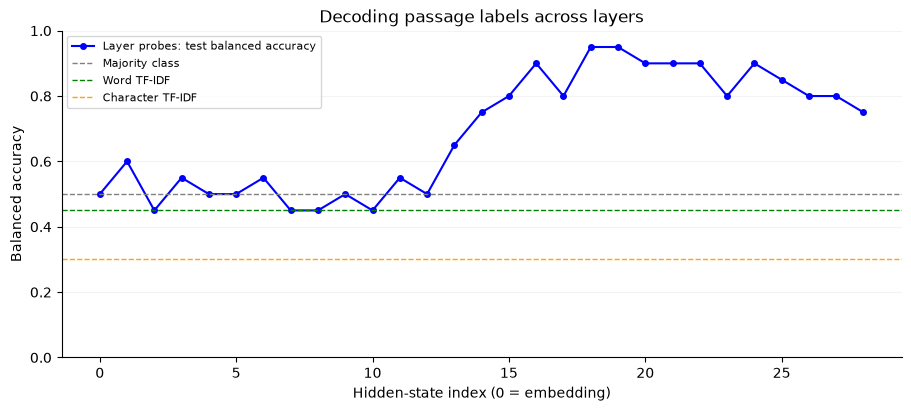

In [71]:
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
ax.plot(range(len(test_scores)), test_scores, "o-", color="blue", markersize=4, label="Layer probes: test balanced accuracy")

for (name, score), color in zip(baselines.items(), ["gray", "green", "orange", "purple"]):
    ax.axhline(score, color=color, linestyle="--", linewidth=1, label=name)

ax.set(xlabel="Hidden-state index (0 = embedding)", ylabel="Balanced accuracy",
       ylim=(0, 1), title="Decoding passage labels across layers")

ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=.15)
ax.legend(fontsize=8)
plt.show()

## 7. Interpretation

The curve describes how well a linear classifier can recover the passage label from each layer's activations on unseen questions. Scores above the baselines support the claim that the activations contain information useful for distinguishing correct from counterfactual passages.

Decodable information does not establish an explicit truth variable, recognition of a falsehood, or causal use of that information when answering. A decline in accuracy at later layers also does not establish that the information has disappeared.

## 8. Save a regenerated run

If you regenerate model responses and activations, the final cell writes them to `data/` and exports `practicum1_upload.zip`, including split assignments and scores. This replaces existing data files and the archive in the working directory. With saved data, all results are already visible above.

In [72]:
if not USE_SAVED_DATA:
    results_dir = Path(".")
    data_dir = results_dir / "data"
    data_dir.mkdir(parents=True, exist_ok=True)
    
    (data_dir / "pilot.json").write_text(json.dumps(pilot, ensure_ascii=False, indent=2), encoding="utf-8")
    np.savez_compressed(
        data_dir / "activations.npz",
        hidden_states=H,
        example_ids=np.asarray(example_ids),
        model_id=pilot["model"]["id"],
        revision=pilot["model"]["revision"],
    )
    
    summary = {
        "experiment": "probing", "seed": SEED,
        "questions_retained": len(selected), "examples": len(examples),
        "question_splits": {
            "train": question_ids[train_q].tolist(),
            "test": question_ids[test_q].tolist(),
        },
        "test_scores_by_layer": test_scores.tolist(),
        "test_predictions_by_layer": layer_predictions.tolist(),
        "test_example_ids": np.asarray(example_ids)[test].tolist(),
        "test_labels": y[test].tolist(),
        "baselines": baselines,
    }
    (data_dir / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")

    export_path = Path("practicum1_upload.zip")
    with zipfile.ZipFile(export_path, "w", compression=zipfile.ZIP_STORED, allowZip64=True) as archive:
        for file in sorted(data_dir.rglob("*")):
            if file.is_file():
                archive.write(file, file.relative_to(results_dir).as_posix())

    print("Saved:", export_path)
    
    try:
        from google.colab import files
    except ImportError:
        display(Markdown(f"[Download results]({export_path.as_posix()})"))
    else:
        files.download(str(export_path))